In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
import seaborn as sns

Gas_Europe = pd.read_csv('/Users/jeanmiccheltia/Downloads/Dutch TTF Natural Gas Futures - Données Historiques.csv')
Brent      = pd.read_csv('/Users/jeanmiccheltia/Downloads/Brent Oil Futures Historical Data.csv')
Coal_Asia  = pd.read_csv('/Users/jeanmiccheltia/Downloads/Newcastle Coal Futures Historical Data UK.csv')
Asia_LNG   = pd.read_csv('/Users/jeanmiccheltia/Downloads/LNG Japan_Korea Marker PLATTS Future Historical Data.csv')
WTI        = pd.read_csv('/Users/jeanmiccheltia/Downloads/Futures pétrole brut WTI - Données Historiques-3.csv')


In [2]:
Gas_Europe.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2274 entries, 0 to 2273
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Date         2274 non-null   object
 1   Dernier      2274 non-null   object
 2   Ouv.         2274 non-null   object
 3    Plus Haut   2274 non-null   object
 4   Plus Bas     2274 non-null   object
 5   Vol.         1793 non-null   object
 6   Variation %  2274 non-null   object
dtypes: object(7)
memory usage: 124.5+ KB


In [3]:
WTI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2561 entries, 0 to 2560
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Date         2561 non-null   object
 1   Dernier      2561 non-null   object
 2   Ouv.         2561 non-null   object
 3    Plus Haut   2561 non-null   object
 4   Plus Bas     2561 non-null   object
 5   Vol.         2465 non-null   object
 6   Variation %  2561 non-null   object
dtypes: object(7)
memory usage: 140.2+ KB


In [4]:
Asia_LNG.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2299 entries, 0 to 2298
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      2299 non-null   object 
 1   Price     2299 non-null   float64
 2   Open      2299 non-null   float64
 3   High      2299 non-null   float64
 4   Low       2299 non-null   float64
 5   Vol.      31 non-null     object 
 6   Change %  2299 non-null   object 
dtypes: float64(4), object(3)
memory usage: 125.9+ KB


In [5]:
Brent.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2534 entries, 0 to 2533
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Date      2534 non-null   object 
 1   Price     2534 non-null   float64
 2   Open      2534 non-null   float64
 3   High      2534 non-null   float64
 4   Low       2534 non-null   float64
 5   Vol.      2533 non-null   object 
 6   Change %  2534 non-null   object 
dtypes: float64(4), object(3)
memory usage: 138.7+ KB


In [6]:
WTI['Date'] = pd.to_datetime(WTI['Date'], format='%d/%m/%Y')
WTI = WTI.rename(columns={'Dernier'    : 'Price',
                          'Ouv.'       : 'Open',
                          ' Plus Haut' : 'High',
                          'Plus Bas'   : 'Low',
                          'Variation %': 'Change %'})


In [7]:
WTI.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2561 entries, 0 to 2560
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      2561 non-null   datetime64[ns]
 1   Price     2561 non-null   object        
 2   Open      2561 non-null   object        
 3   High      2561 non-null   object        
 4   Low       2561 non-null   object        
 5   Vol.      2465 non-null   object        
 6   Change %  2561 non-null   object        
dtypes: datetime64[ns](1), object(6)
memory usage: 140.2+ KB


In [8]:
Gas_Europe['Date'] = pd.to_datetime(Gas_Europe['Date'], format='%d/%m/%Y')
Asia_LNG['Date'] = pd.to_datetime(Asia_LNG['Date'], format='%m/%d/%Y')
Coal_Asia['Date'] = pd.to_datetime(Coal_Asia['Date'], format='%d/%m/%Y')
Brent['Date'] = pd.to_datetime(Brent['Date'],format='%m/%d/%Y')

In [9]:

Gas_Europe = Gas_Europe.rename(columns={'Dernier'    : 'Price',
                          'Ouv.'       : 'Open',
                          ' Plus Haut' : 'High',
                          'Plus Bas'   : 'Low',
                          'Variation %': 'Change %'})


Cols = ['Price','Open','High','Low']
Gas_Europe[Cols] = (
    Gas_Europe[Cols]
    .replace({r"\.": "", ",": "."}, regex=True)
    .apply(pd.to_numeric, errors="coerce"))

Gas_Europe.head(3)

,Date,Price,Open,High,Low,Vol.,Change %
0,2026-10-23,93.853,92.970,94.025,92.570,"0,34K","3,93%"
1,2026-10-22,90.300,90.095,91.100,90.015,"0,27K","3,29%"
2,2026-10-21,87.426,87.400,88.605,86.380,"0,18K","2,78%"


In [10]:
WTI[Cols] = (
    WTI[Cols]
    .replace({r"\.": "", ",": "."}, regex=True)
    .apply(pd.to_numeric, errors="coerce"))
WTI.head(3)

,Date,Price,Open,High,Low,Vol.,Change %
0,2026-10-23,103.44,99.08,103.91,99.09,"309,75K","3,99%"
1,2026-10-22,99.47,97.78,100.17,97.72,"301,81K","2,39%"
2,2026-10-21,97.15,98.19,100.40,96.26,"332,17K","-0,68%"


In [11]:
from functools import reduce

start = pd.to_datetime('2017-10-23')
end   = pd.to_datetime('2026-10-23')

cols_need = ['Date', 'Price']

Gas_Europe_df = Gas_Europe[cols_need].copy()
Asia_LNG_df = Asia_LNG[cols_need].copy()
Coal_Asia_df = Coal_Asia[cols_need].copy()
Brent_df = Brent[cols_need].copy()
WTI_df  = WTI[cols_need].copy()

Gas_Europe_df = Gas_Europe_df.rename(columns={'Price': 'Gas_Europe'})
Asia_LNG_df = Asia_LNG_df.rename(columns={'Price': 'Asia_LNG'})
Coal_Asia_df = Coal_Asia_df.rename(columns={'Price': 'Coal_Asia'})
Brent_df = Brent_df.rename(columns={'Price': 'Brent'})
WTI_df = WTI_df.rename(columns={'Price': 'WTI'})

dfs = [Gas_Europe_df, Asia_LNG_df, Coal_Asia_df, Brent_df, WTI_df]

data = reduce(
    lambda left, right: pd.merge(left, right, on='Date', how='outer'),
    dfs
)

df  = data.loc[(data['Date'] >= start)
    & (data['Date'] <= end)].sort_values('Date').reset_index(drop=True)
df.head(3)

,Date,Gas_Europe,Asia_LNG,Coal_Asia,Brent,WTI
0,2017-10-23,18.09,8.820,96.55,57.37,52.08
1,2017-10-24,17.96,8.820,97.20,58.33,52.67
2,2017-10-25,18.11,8.785,97.15,58.44,52.43


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2370 entries, 0 to 2369
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   Date        2370 non-null   datetime64[ns]
 1   Gas_Europe  2274 non-null   float64       
 2   Asia_LNG    2265 non-null   float64       
 3   Coal_Asia   2325 non-null   float64       
 4   Brent       2325 non-null   float64       
 5   WTI         2364 non-null   float64       
dtypes: datetime64[ns](1), float64(5)
memory usage: 111.2 KB


In [13]:
df = df.ffill(limit=3)
print(df.isna().sum())

Date          0
Gas_Europe    0
Asia_LNG      0
Coal_Asia     0
Brent         0
WTI           0
dtype: int64


In [14]:
!pip install ecb-currency-exchange-rate

In [15]:
start = '2017-10-23'
end = '2026-10-23'

url = (
    "https://data-api.ecb.europa.eu/service/data/"
    "EXR/D.USD.EUR.SP00.A"
    f"?startPeriod={start}&endPeriod={end}&format=csvdata"
)

exchange_df = pd.read_csv(url)

exchange_df = exchange_df[
    ['TIME_PERIOD', 'OBS_VALUE']
].rename(columns={
    'TIME_PERIOD': 'Date',
    'OBS_VALUE': 'Exchange_Rate'
})

exchange_df['Date'] = pd.to_datetime(exchange_df['Date'])
exchange_df = exchange_df.sort_values('Date').reset_index(drop=True)

exchange_df.head(3)

,Date,Exchange_Rate
0,2017-10-23,1.1740
1,2017-10-24,1.1761
2,2017-10-25,1.1785


In [16]:
exchange_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2304 entries, 0 to 2303
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Date           2304 non-null   datetime64[ns]
 1   Exchange_Rate  2304 non-null   float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 36.1 KB


In [17]:
df_data = pd.merge(df,exchange_df,on ='Date', how='left')
df_data = df_data.ffill(limit=3)
print(df_data.isna().sum())

Date             0
Gas_Europe       0
Asia_LNG         0
Coal_Asia        0
Brent            0
WTI              0
Exchange_Rate    0
dtype: int64


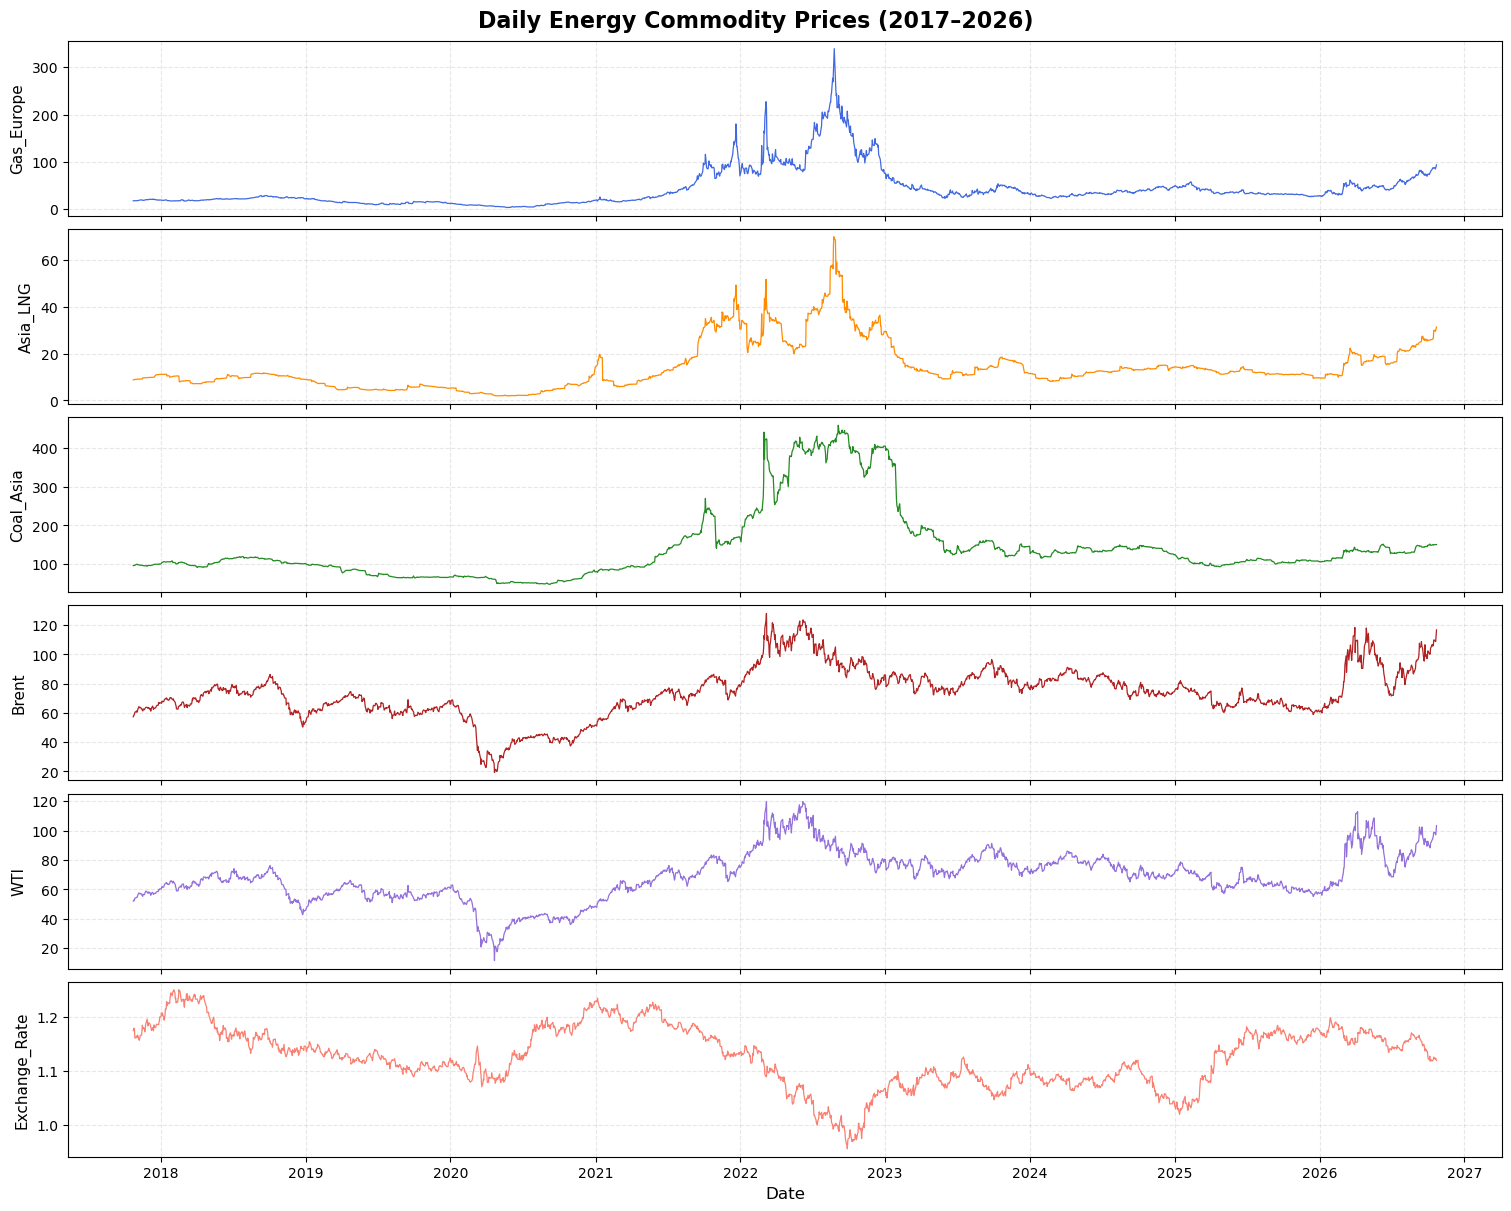

In [18]:
import matplotlib.dates as mdates

commodities = [
    'Gas_Europe',
    'Asia_LNG',
    'Coal_Asia',
    'Brent',
    'WTI',
    'Exchange_Rate'
]

colors = [
    'royalblue',
    'darkorange',
    'forestgreen',
    'firebrick',
    'mediumpurple',
    'salmon'
]

fig, axes = plt.subplots(
    len(commodities), 1,
    figsize=(15, 12),
    sharex=True,
    constrained_layout=True
)

for ax, commodity, color in zip(axes, commodities, colors):
    ax.plot(
        df_data['Date'],
        df_data[commodity],
        color=color,
        linewidth=0.9
    )

    ax.set_ylabel(commodity, fontsize=11)
    ax.grid(alpha=0.3, linestyle='--')


axes[-1].xaxis.set_major_locator(mdates.YearLocator())
axes[-1].xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
axes[-1].set_xlabel('Date', fontsize=12)

fig.suptitle(
    'Daily Energy Commodity Prices (2017–2026)',
    fontsize=16,
    fontweight='bold'
)

plt.show()

1. the Asia LNG and TTF are interconnected, therefore follow similar path , with Asia LNG offering slightly higher price to have shipping
shipment diverted to their 
2. Coal tend to be an alternative in Asia therefore the increasing prices
3. WTI and Brent following the same trend
4. following the war in Ukraine there is a new overall trend with all following a rising path
5. Exchange rate contained within 1.1-1.2 

In [20]:
print(df_data.columns.tolist())

['Date', 'Gas_Europe', 'Asia_LNG', 'Coal_Asia', 'Brent', 'WTI', 'Exchange_Rate']


In [21]:
from statsmodels.tsa.stattools import adfuller

series = df_data['Gas_Europe'].dropna()

print("Type:", type(series))
print("Shape:", series.shape)
print("Dimensions:", series.ndim)

result = adfuller(series, autolag='AIC', regression='c')

print("ADF Statistic:", result[0])
print("p-value:", result[1])

Type: <class 'pandas.core.series.Series'>
Shape: (2370,)
Dimensions: 1
ADF Statistic: -2.2933336446497403
p-value: 0.17412701889998566


In [22]:

from statsmodels.tsa.stattools import adfuller
import pandas as pd

variables = [
    'Gas_Europe',
    'Asia_LNG',
    'Coal_Asia',
    'Brent',
    'WTI',
    'Exchange_Rate'
]

results = []

for variable in variables:
    series = df_data[variable].dropna()

    adf = adfuller(series, autolag='AIC', regression='c')

    results.append({
        'Variable': variable,
        'ADF Statistic': adf[0],
        'p-value': adf[1],
        'Lags': adf[2],
        'Observations': adf[3],
        'Stationary (5%)': adf[1] < 0.05
    })

adf_table = pd.DataFrame(results)
display(adf_table.round(4))


,Variable,ADF Statistic,p-value,Lags,Observations,Stationary (5%)
0,Gas_Europe,-2.2933,0.1741,16,2353,False
1,Asia_LNG,-2.1738,0.2159,24,2345,False
2,Coal_Asia,-1.5939,0.4866,27,2342,False
3,Brent,-1.7684,0.3963,12,2357,False
4,WTI,-1.8827,0.3403,12,2357,False
5,Exchange_Rate,-2.2709,0.1815,0,2369,False


In [23]:
for variable in variables:
    series = pd.to_numeric(df_data[variable], errors='coerce')
    series = np.log(series.where(series > 0)).dropna()
    adf = adfuller(series, autolag='AIC', regression='c')

    results.append({
        'Variable': variable,
        'ADF Statistic': adf[0],
        'p-value': adf[1],
        'Lags': adf[2],
        'Observations': adf[3],
        'Stationary (5%)': adf[1] < 0.05
    })

adf_table = pd.DataFrame(results)
display(adf_table.round(4))

,Variable,ADF Statistic,p-value,Lags,Observations,Stationary (5%)
0,Gas_Europe,-2.2933,0.1741,16,2353,False
1,Asia_LNG,-2.1738,0.2159,24,2345,False
2,Coal_Asia,-1.5939,0.4866,27,2342,False
3,Brent,-1.7684,0.3963,12,2357,False
4,WTI,-1.8827,0.3403,12,2357,False
5,Exchange_Rate,-2.2709,0.1815,0,2369,False
6,Gas_Europe,-1.2891,0.6342,4,2365,False
7,Asia_LNG,-1.1673,0.6875,0,2369,False
8,Coal_Asia,-1.3058,0.6265,26,2343,False
9,Brent,-1.9515,0.3082,11,2358,False


In [24]:
for variable in variables:
    series = pd.to_numeric(df_data[variable], errors='coerce')
    
    series = np.log(series.where(series > 0)).diff().dropna()
    adf = adfuller(series, autolag='AIC', regression='c')

    results.append({
        'Variable': variable,
        'ADF Statistic': adf[0],
        'p-value': adf[1],
        'Lags': adf[2],
        'Observations': adf[3],
        'Stationary (5%)': adf[1] < 0.05
    })

adf_table = pd.DataFrame(results)
display(adf_table.round(4))

,Variable,ADF Statistic,p-value,Lags,Observations,Stationary (5%)
0,Gas_Europe,-2.2933,0.1741,16,2353,False
1,Asia_LNG,-2.1738,0.2159,24,2345,False
2,Coal_Asia,-1.5939,0.4866,27,2342,False
3,Brent,-1.7684,0.3963,12,2357,False
4,WTI,-1.8827,0.3403,12,2357,False
5,Exchange_Rate,-2.2709,0.1815,0,2369,False
6,Gas_Europe,-1.2891,0.6342,4,2365,False
7,Asia_LNG,-1.1673,0.6875,0,2369,False
8,Coal_Asia,-1.3058,0.6265,26,2343,False
9,Brent,-1.9515,0.3082,11,2358,False


In [25]:
from statsmodels.tsa.stattools import coint
series2 = pd.to_numeric(df_data['Gas_Europe'], errors='coerce')
Series2 = np.log(series2.where(series2 > 0)).dropna()
series1 = pd.to_numeric(df_data['Asia_LNG'], errors='coerce')
Series1 = np.log(series1.where(series1 > 0)).dropna()
score, p_value, critical_values = coint(Series1,Series2)

print("---Engle-Granger Cointegration Test Results ----")
print(f't-statistic : {score:.4f}')
print(f'p-value : {p_value:.4f}')
print('Critical Values : ')
print(f' 1% : {critical_values[0]:.4f}')
print(f' 5% : {critical_values[1]:.4f}')
print(f' 10% : {critical_values[2]:.4f}')

alpha = 0.05
if p_value < alpha:
    print('\nResult: Reject the null hypothesis.')
    print('Conclusion : bother series have a long term relationship')
else :
    print('\nResult: Fail to reject the null hypothesis.')
    print('Conclusion : bother series are not cointegrated')
    

---Engle-Granger Cointegration Test Results ----
t-statistic : -7.1609
p-value : 0.0000
Critical Values : 
 1% : -3.9011
 5% : -3.3387
 10% : -3.0462

Result: Reject the null hypothesis.
Conclusion : bother series have a long term relationship


In [26]:
from statsmodels.tsa.stattools import coint
series3 = pd.to_numeric(df_data['Coal_Asia'], errors='coerce')
Series3 = np.log(series3.where(series3 > 0)).dropna()

score1, p_value1, critical_values1 = coint(Series1,Series3)

print("---Engle-Granger Cointegration Test Results ----")
print(f't-statistic : {score1:.4f}')
print(f'p-value : {p_value1:.4f}')
print('Critical Values : ')
print(f' 1% : {critical_values1[0]:.4f}')
print(f' 5% : {critical_values1[1]:.4f}')
print(f' 10% : {critical_values1[2]:.4f}')

alpha = 0.05
if p_value < alpha:
    print('\nResult: Reject the null hypothesis.')
    print('Conclusion : bother series have a long term relationship')
else :
    print('\nResult: Fail to reject the null hypothesis.')
    print('Conclusion : bother series are not cointegrated')
    

---Engle-Granger Cointegration Test Results ----
t-statistic : -3.0097
p-value : 0.1079
Critical Values : 
 1% : -3.9011
 5% : -3.3387
 10% : -3.0462

Result: Reject the null hypothesis.
Conclusion : bother series have a long term relationship


In [27]:
score2, p_value2, critical_values2 = coint(Series2,Series3)

print("---Engle-Granger Cointegration Test Results ----")
print(f't-statistic : {score2:.4f}')
print(f'p-value : {p_value2:.4f}')
print('Critical Values : ')
print(f' 1% : {critical_values2[0]:.4f}')
print(f' 5% : {critical_values2[1]:.4f}')
print(f' 10% : {critical_values2[2]:.4f}')

alpha = 0.05
if p_value < alpha:
    print('\nResult: Reject the null hypothesis.')
    print('Conclusion : bother series have a long term relationship')
else :
    print('\nResult: Fail to reject the null hypothesis.')
    print('Conclusion : bother series are not cointegrated')

---Engle-Granger Cointegration Test Results ----
t-statistic : -3.5711
p-value : 0.0266
Critical Values : 
 1% : -3.9011
 5% : -3.3387
 10% : -3.0462

Result: Reject the null hypothesis.
Conclusion : bother series have a long term relationship


In [28]:
from statsmodels.tsa.vector_ar.vecm import coint_johansen
series4 = pd.to_numeric(df_data['Brent'], errors='coerce')
Series4 = np.log(series4.where(series3 > 0)).dropna()

data_johansen = pd.DataFrame({'Enrope_Gas_log': Series2, 'Asia_LNG_log':Series1,
                              'Coal_Asia_log': Series3, 'Brent': Series4})
result = coint_johansen(data_johansen, det_order=0, k_ar_diff=1)

def print_johansen_results(res):
    print('--Johansen Cointegration Test Results---')
    print(f'{'Rank':<8}{'Trace Stat':<15}{'Crit 95% (Trace)':<18}{'Max-Eig Stat':<15}{'Crit 95% (Mx-Eig)':<18}')
    print('-'*74)

    for i in range(len(res.lr1)):
        print(f'r <= {i:<4}'
              f'{res.lr1[i]:<15.4f}'
              f'{res.cvt[i, 1]:<18.4f}'
              f'{res.lr2[i]:<15.4f}'
              f'{res.cvm[i, 1]:<18.4f}')
print_johansen_results(result)

--Johansen Cointegration Test Results---
Rank    Trace Stat     Crit 95% (Trace)  Max-Eig Stat   Crit 95% (Mx-Eig) 
--------------------------------------------------------------------------
r <= 0   106.6140       47.8545           67.2425        27.5858           
r <= 1   39.3714        29.7961           21.2226        21.1314           
r <= 2   18.1488        15.4943           17.0025        14.2639           
r <= 3   1.1463         3.8415            1.1463         3.8415            


In [29]:
from statsmodels.tsa.vector_ar.var_model import VAR

model = VAR(data_johansen )
lag_selection = model.select_order(maxlags=20)

print('--Lag Selection Summary----')
print(lag_selection)
optimal_lag_aic = lag_selection.aic

print(f'\nOptimal lag length chosen by AIC: {optimal_lag_aic}')
var_results = model.fit(optimal_lag_aic)

print('\n---VAR Estimation Results Summary ----')
print(var_results.summary())

--Lag Selection Summary----
<statsmodels.tsa.vector_ar.var_model.LagOrderResults object. Selected orders are: AIC -> 6, BIC -> 1, FPE -> 6, HQIC ->  2>

Optimal lag length chosen by AIC: 6

---VAR Estimation Results Summary ----
  Summary of Regression Results   
Model:                         VAR
Method:                        OLS
Date:           Mon, 26, Oct, 2026
Time:                     21:43:07
--------------------------------------------------------------------
No. of Equations:         4.00000    BIC:                   -27.2175
Nobs:                     2364.00    HQIC:                  -27.3727
Log likelihood:           19142.0    FPE:                1.18471e-12
AIC:                     -27.4615    Det(Omega_mle):     1.13589e-12
--------------------------------------------------------------------
Results for equation Enrope_Gas_log
                       coefficient       std. error           t-stat            prob
-------------------------------------------------------------

All correlations are positive but weak, the srongest correlation is between TTF price (Europe Gas) and JMK 
(Asia LNG) stands at 0.36 , folowed by Coal and TTF at 0.22, with the lowest between Brent price and Asia LNG
It suggest that the price could be passed on other commodities within 6 trading days
This suggests that both commodities experienced some common shocks, potentially reflecting fuel substitution and global energy market disruptions coal and European natural gas can experience common shocks because global energy markets are interconnected through several mechanisms:

1. Fuel substitution: When European natural gas prices rise, electricity producers may switch from gas to coal, increasing coal demand and prices.
2. Russia–Ukraine war (2022): Disruptions to Russian energy supplies increased European demand for alternative fuels, including imported coal, affecting global coal markets.
3. Global energy demand: Economic recovery after COVID-19 increased demand for both natural gas and coal, putting upward pressure on prices.
4. LNG competition: Increased European LNG imports can raise global gas prices, encouraging gas-to-coal switching in Asian electricity markets.

In [31]:
from statsmodels.tsa.vector_ar.vecm import VECM, select_order, select_coint_rank
model    = VECM(data_johansen, k_ar_diff = 5, coint_rank= 3,  deterministic="ci")
vecm_res = model.fit()
print(vecm_res.summary())

Det. terms outside the coint. relation & lagged endog. parameters for equation Enrope_Gas_log
                        coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
L1.Enrope_Gas_log     0.0403      0.023      1.750      0.080      -0.005       0.085
L1.Asia_LNG_log       0.0314      0.026      1.217      0.224      -0.019       0.082
L1.Coal_Asia_log      0.0003      0.044      0.007      0.994      -0.087       0.087
L1.Brent              0.0103      0.040      0.259      0.796      -0.068       0.088
L2.Enrope_Gas_log    -0.0399      0.023     -1.723      0.085      -0.085       0.005
L2.Asia_LNG_log      -0.0167      0.026     -0.647      0.517      -0.067       0.034
L2.Coal_Asia_log     -0.0123      0.044     -0.277      0.781      -0.099       0.075
L2.Brent             -0.0038      0.040     -0.096      0.924      -0.082       0.074
L3.Enrope_Gas_log    -0.0241      0.023     -1

Interpretation of the updated VECM results
- European Gas: EC1 (−0.0233, p = 0.001) and EC2 (0.0223, p = 0.002) remain significant, indicating adjustment to long-run disequilibria.
- Asian LNG: All three error-correction terms remain significant (p < 0.05), suggesting strong responsiveness to long-run disequilibria.
- Asian Coal: Only EC3 (−0.0085, p < 0.001) is significant, indicating adjustment through the third cointegrating relationship.
- Brent Oil: None of the error-correction terms is significant, suggesting limited evidence of long-run adjustment.
Conclusion
The results are robust to this small change in lag specification. European gas and Asian LNG exhibit the clearest long-run adjustment responses, Asian coal adjusts through one relationship, while Brent shows no statistically significant individual error-correction coefficients.

Brent behave as a leader , pushing other commodities rather than responding to them, for Gas when prices change
particularly in Europe LNG cargoes move between Europe and Asia

In [32]:
granger_test_1 = vecm_res.test_granger_causality(caused='Asia_LNG_log', causing='Enrope_Gas_log')
print(granger_test_1.summary())

Granger causality F-test. H_0: Enrope_Gas_log does not Granger-cause Asia_LNG_log. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         14.91          2.100   0.000 (6, 9336)
-----------------------------------------------


In [33]:
granger_test_2 = vecm_res.test_granger_causality(caused='Enrope_Gas_log', causing='Asia_LNG_log')
print(granger_test_2.summary())

Granger causality F-test. H_0: Asia_LNG_log does not Granger-cause Enrope_Gas_log. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         2.659          2.100   0.014 (6, 9336)
-----------------------------------------------


In [34]:
granger_test_3 = vecm_res.test_granger_causality(caused='Coal_Asia_log', causing='Enrope_Gas_log')
print(granger_test_3.summary())

Granger causality F-test. H_0: Enrope_Gas_log does not Granger-cause Coal_Asia_log. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         4.508          2.100   0.000 (6, 9336)
-----------------------------------------------


In [35]:
granger_test_4 = vecm_res.test_granger_causality(caused='Enrope_Gas_log', causing='Coal_Asia_log')
print(granger_test_4.summary())

Granger causality F-test. H_0: Coal_Asia_log does not Granger-cause Enrope_Gas_log. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         1.008          2.100   0.418 (6, 9336)
-----------------------------------------------


In [36]:
granger_test_5 = vecm_res.test_granger_causality(caused='Asia_LNG_log', causing='Coal_Asia_log')
print(granger_test_5.summary())

Granger causality F-test. H_0: Coal_Asia_log does not Granger-cause Asia_LNG_log. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         3.168          2.100   0.004 (6, 9336)
-----------------------------------------------


In [38]:
granger_test_6 = vecm_res.test_granger_causality(caused='Coal_Asia_log', causing='Asia_LNG_log')
print(granger_test_6.summary())

Granger causality F-test. H_0: Asia_LNG_log does not Granger-cause Coal_Asia_log. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value     df   
-----------------------------------------------
         2.168          2.100   0.043 (6, 9336)
-----------------------------------------------


European Gas directly leads Asian coal, but coal does in any case influence European gas. The ttf
drives coal and LNG in Asia, but LNG Asia also influence European gas but not as much as in the other way
Asia LNG and Coal influence each other but Coal more , showing a predominance of Coal over LNG in Asia with
Brent staying the external driver in the long run

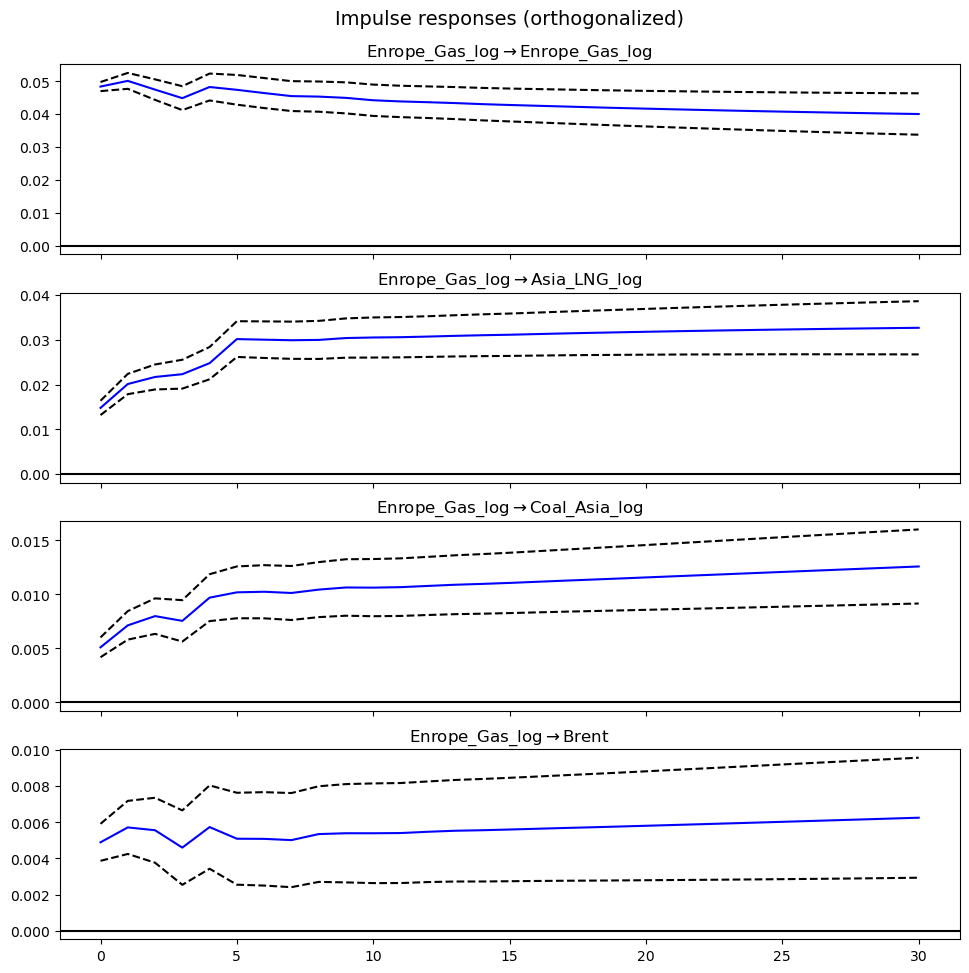

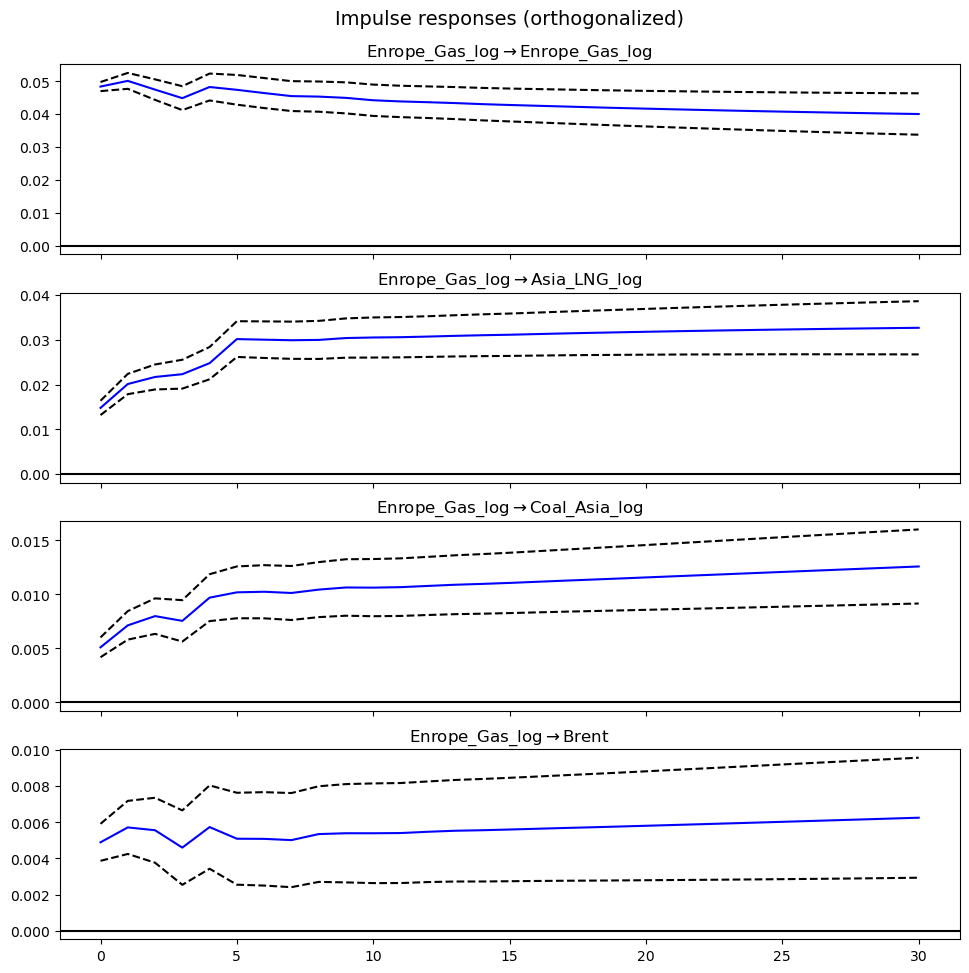

In [40]:
irf = vecm_res.irf(30)
irf.plot(impulse='Enrope_Gas_log', orth=True)

The impulse response functions (IRFs) indicate that a positive shock to European natural gas prices generates positive and persistent responses across all four energy markets over the 30-period horizon.
- European Gas: Strong positive own-price response, gradually declining but remaining persistent.
- Asian LNG: Substantial positive response, increasing initially before stabilizing, suggesting strong cross-market transmission.
- Asian Coal: Moderate positive response that increases gradually, indicating potential spillovers through fuel substitution and interconnected energy markets.
- Brent Oil: Smaller but persistent positive response, suggesting weaker transmission from European gas to crude oil.
Conclusion: European natural gas shocks are associated with positive responses across global energy markets, particularly Asian LNG. All displayed confidence bands remain above zero, suggesting statistically significant positive responses, assuming they represent valid confidence intervals

In [42]:
cols = ['Enrope_Gas_log','Asia_LNG_log','Coal_Asia_log', 'Brent']
coal_resp = irf.orth_irfs[:,cols.index('Coal_Asia_log') ,cols.index('Enrope_Gas_log')]
final = coal_resp[-1]
day_90 = np.argmax(coal_resp  >= 0.9 * final)

print(f'final response: {final:.4f}')
print(f'90% reached after {day_90} trading days'
      f'approximatively {day_90*7 / 5:.0f} calendar days)')

final response: 0.0126
90% reached after 18 trading daysapproximatively 25 calendar days)


## CHeck of the Robustness

In [45]:
start_prior = pd.to_datetime('2017-10-23')
end_prior = pd.to_datetime('2020-10-23')

start_post = pd.to_datetime('2021-01-01')
end_post = pd.to_datetime('2026-10-23')

Prior_data  = df_data.loc[(df_data['Date'] >= start_prior)
    & (df_data['Date'] <= end_prior)].sort_values('Date').reset_index(drop=True)
Post_data  = df_data.loc[(df_data['Date'] >= start_post)
    & (df_data['Date'] <= end_post)].sort_values('Date').reset_index(drop=True)

print(Prior_data .head(3))
print(Post_data .head(3))

        Date  Gas_Europe  Asia_LNG  Coal_Asia  Brent    WTI  Exchange_Rate
0 2017-10-23       18.09     8.820      96.55  57.37  52.08         1.1740
1 2017-10-24       17.96     8.820      97.20  58.33  52.67         1.1761
2 2017-10-25       18.11     8.785      97.15  58.44  52.43         1.1785
        Date  Gas_Europe  Asia_LNG  Coal_Asia  Brent    WTI  Exchange_Rate
0 2021-01-04      19.845    14.930      81.20  51.09  47.76         1.2296
1 2021-01-05      18.005    15.105      80.35  53.60  50.01         1.2271
2 2021-01-06      17.565    15.550      79.45  54.30  50.69         1.2338


In [46]:
cols_num = ['Gas_Europe', 'Asia_LNG', 'Coal_Asia', 'Brent', 'WTI']
Prior_data[cols_num] = np.log(Prior_data[cols_num])
Post_data[cols_num] = np.log(Post_data[cols_num])

Prior_data_df = Prior_data.drop(columns=['Date', 'WTI', 'Exchange_Rate'])
Post_data_df = Post_data.drop(columns=['Date', 'WTI', 'Exchange_Rate'])

def run_vecm(data, maxlags=20):

    df = data.select_dtypes(include='number').copy()
    df = df.sort_index().replace(
        [np.inf, -np.inf], np.nan
    ).dropna()

    lag_selection = VAR(df).select_order(maxlags=maxlags)
    optimal_lag = lag_selection.aic

    k_ar_diff = max(optimal_lag - 1, 0)

    rank_result = select_coint_rank(
        df,
        det_order=0,
        k_ar_diff=k_ar_diff,
        method='trace',
        signif=0.05
    )

    rank = rank_result.rank


    model = VECM(
        df,
        k_ar_diff=k_ar_diff,
        coint_rank=rank,
        deterministic='ci'
    )

    results = model.fit()

    print(f"Optimal VAR lag: {optimal_lag}")
    print(f"VECM difference lags: {k_ar_diff}")
    print(f"Cointegration rank: {rank}")

    return results

In [47]:
results_1 = run_vecm(Prior_data_df,maxlags=20)

Optimal VAR lag: 1
VECM difference lags: 0
Cointegration rank: 2


In [50]:
cols_num = ['Gas_Europe', 'Asia_LNG', 'Coal_Asia', 'Brent']

def run_vecm(data, cols_num, maxlags=20):

    df = data[cols_num].copy()
    df = df.sort_index()
    df = df.apply(pd.to_numeric, errors='coerce')
    df = df.replace([np.inf, -np.inf], np.nan).dropna()

    
    lag_selection = VAR(df).select_order(maxlags=maxlags)
    optimal_lag = lag_selection.aic
    k_ar_diff = max(optimal_lag - 1, 0)

    
    rank_result = select_coint_rank(
        df,
        det_order=0,
        k_ar_diff=k_ar_diff)

    rank = rank_result.rank

    if rank == 0:
        raise ValueError(
            "No cointegration detected"
        )

    model = VECM(
        df,
        k_ar_diff=k_ar_diff,
        coint_rank=rank,
        deterministic='ci'
    )

    results = model.fit()

    print("Optimal VAR lag:", optimal_lag)
    print("VECM difference lags:", k_ar_diff)
    print("Cointegration rank:", rank)

    return results


In [51]:
vecm_res_1 = run_vecm(Prior_data_df, cols_num)
print(vecm_res_1.summary())

Optimal VAR lag: 1
VECM difference lags: 0
Cointegration rank: 2
             Loading coefficients (alpha) for equation Gas_Europe             
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ec1           -0.0378      0.011     -3.588      0.000      -0.058      -0.017
ec2            0.0410      0.010      4.206      0.000       0.022       0.060
              Loading coefficients (alpha) for equation Asia_LNG              
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ec1            0.0294      0.010      3.077      0.002       0.011       0.048
ec2           -0.0165      0.009     -1.870      0.061      -0.034       0.001
             Loading coefficients (alpha) for equation Coal_Asia              
                 coef    std err          z      P>|z|      [0.025

In [52]:
print(vecm_res_1.test_whiteness(nlags=20).summary())

Portmanteau-test for residual autocorrelation. H_0: residual autocorrelation up to lag 20 is zero. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value  df
-----------------------------------------
         479.8          354.2   0.000 312
-----------------------------------------


In [53]:
vecm_res_2 = run_vecm(Post_data_df, cols_num)
print(vecm_res_2.summary())

Optimal VAR lag: 6
VECM difference lags: 5
Cointegration rank: 1
Det. terms outside the coint. relation & lagged endog. parameters for equation Gas_Europe
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
L1.Gas_Europe     0.0126      0.030      0.422      0.673      -0.046       0.071
L1.Asia_LNG       0.0742      0.034      2.212      0.027       0.008       0.140
L1.Coal_Asia      0.0180      0.053      0.338      0.735      -0.086       0.123
L1.Brent          0.0339      0.059      0.570      0.569      -0.083       0.150
L2.Gas_Europe    -0.0641      0.030     -2.132      0.033      -0.123      -0.005
L2.Asia_LNG       0.0032      0.034      0.094      0.925      -0.063       0.069
L2.Coal_Asia     -0.0255      0.053     -0.480      0.631      -0.130       0.079
L2.Brent          0.0223      0.059      0.374      0.708      -0.094       0.139
L3.Gas_Europe    -0.0259 

the results suggest that European gas, Asian LNG, Asian coal, and Brent share a long-run equilibrium relationship. However, Asian LNG is the only market exhibiting a statistically significant individual adjustment to deviations from that relationship.
Short-run interactions are also present, particularly between European natural gas and Asian LNG, indicating interconnected market dynamics.
This could reflect international LNG trade, competition for gas supplies, and energy market substitution

In [57]:
granger_test_set_1 = vecm_res_1.test_granger_causality(caused='Asia_LNG', causing='Gas_Europe')
print(granger_test_set_1.summary())

Granger causality F-test. H_0: Gas_Europe does not Granger-cause Asia_LNG. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value               df             
-------------------------------------------------------------------
         4.407          3.844   0.036 (np.int64(1), np.int64(3132))
-------------------------------------------------------------------


In [58]:
granger_test_set_2 = vecm_res_1.test_granger_causality(caused='Coal_Asia', causing='Gas_Europe')
print(granger_test_set_2.summary())

Granger causality F-test. H_0: Gas_Europe does not Granger-cause Coal_Asia. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value               df             
-------------------------------------------------------------------
         1.355          3.844   0.245 (np.int64(1), np.int64(3132))
-------------------------------------------------------------------


In [60]:
granger_test_set_3 = vecm_res_1.test_granger_causality(caused='Coal_Asia', causing='Asia_LNG')
print(granger_test_set_3.summary())

Granger causality F-test. H_0: Asia_LNG does not Granger-cause Coal_Asia. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value               df             
-------------------------------------------------------------------
        0.4973          3.844   0.481 (np.int64(1), np.int64(3132))
-------------------------------------------------------------------


In [61]:
granger_test_set_4 = vecm_res_1.test_granger_causality(caused='Gas_Europe', causing='Asia_LNG')
print(granger_test_set_4.summary())

Granger causality F-test. H_0: Asia_LNG does not Granger-cause Gas_Europe. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value               df             
-------------------------------------------------------------------
         1.345          3.844   0.246 (np.int64(1), np.int64(3132))
-------------------------------------------------------------------


In [62]:
granger_test_set_5 = vecm_res_2.test_granger_causality(caused='Asia_LNG', causing='Gas_Europe')
print(granger_test_set_5.summary())

Granger causality F-test. H_0: Gas_Europe does not Granger-cause Asia_LNG. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value               df             
-------------------------------------------------------------------
         17.62          2.100   0.000 (np.int64(6), np.int64(5968))
-------------------------------------------------------------------


In [63]:
granger_test_set_6 = vecm_res_2.test_granger_causality(caused='Coal_Asia', causing='Asia_LNG')
print(granger_test_set_6.summary())

Granger causality F-test. H_0: Asia_LNG does not Granger-cause Coal_Asia. Conclusion: fail to reject H_0 at 5% significance level.
Test statistic Critical value p-value               df             
-------------------------------------------------------------------
         1.383          2.100   0.217 (np.int64(6), np.int64(5968))
-------------------------------------------------------------------


The European Gas price have led Asian LNG throughout 2017-2026, the transmission to Coal price appeared from 2021 when Energy crisis started
need to note that the post period is shorter 3 years and 2 months while the post period is 7 years and 10 months

In [64]:
granger_test_set_7 = vecm_res_2.test_granger_causality(caused='Coal_Asia', causing='Gas_Europe')
print(granger_test_set_7.summary())

Granger causality F-test. H_0: Gas_Europe does not Granger-cause Coal_Asia. Conclusion: reject H_0 at 5% significance level.
Test statistic Critical value p-value               df             
-------------------------------------------------------------------
         3.824          2.100   0.001 (np.int64(6), np.int64(5968))
-------------------------------------------------------------------


In [65]:
irf = vecm_res_2.irf(30)
coal_resp = irf.orth_irfs[:,cols_num.index('Coal_Asia') ,cols_num.index('Gas_Europe')]
final = coal_resp[-1]
day_90 = np.argmax(coal_resp  >= 0.9 * final)

print(f'final response: {final:.4f}')
print(f'90% reached after {day_90} trading days'
      f'approximatively {day_90*7 / 5:.0f} calendar days)')

final response: 0.0128
90% reached after 4 trading daysapproximatively 6 calendar days)


Since 2021 a deviation shock to TTF saise Asian coal prices by about 1.3% with 90% of the effect within 4 trading days 

In [66]:
df_data.head(5)

,Date,Gas_Europe,Asia_LNG,Coal_Asia,Brent,WTI,Exchange_Rate
0,2017-10-23,18.09,8.820,96.55,57.37,52.08,1.1740
1,2017-10-24,17.96,8.820,97.20,58.33,52.67,1.1761
2,2017-10-25,18.11,8.785,97.15,58.44,52.43,1.1785
3,2017-10-26,18.07,8.850,97.10,59.30,52.86,1.1753
4,2017-10-27,18.15,8.995,97.45,60.44,54.09,1.1605


In [68]:
df_data['TTF'] = (df_data['Gas_Europe'] * df_data['Exchange_Rate']).round(2)
df_data.head(5)

,Date,Gas_Europe,Asia_LNG,Coal_Asia,Brent,WTI,Exchange_Rate,TTF
0,2017-10-23,18.09,8.820,96.55,57.37,52.08,1.1740,21.24
1,2017-10-24,17.96,8.820,97.20,58.33,52.67,1.1761,21.12
2,2017-10-25,18.11,8.785,97.15,58.44,52.43,1.1785,21.34
3,2017-10-26,18.07,8.850,97.10,59.30,52.86,1.1753,21.24
4,2017-10-27,18.15,8.995,97.45,60.44,54.09,1.1605,21.06


lets normalise the normalise figures to show the growth from the start to compare the commodities in growth

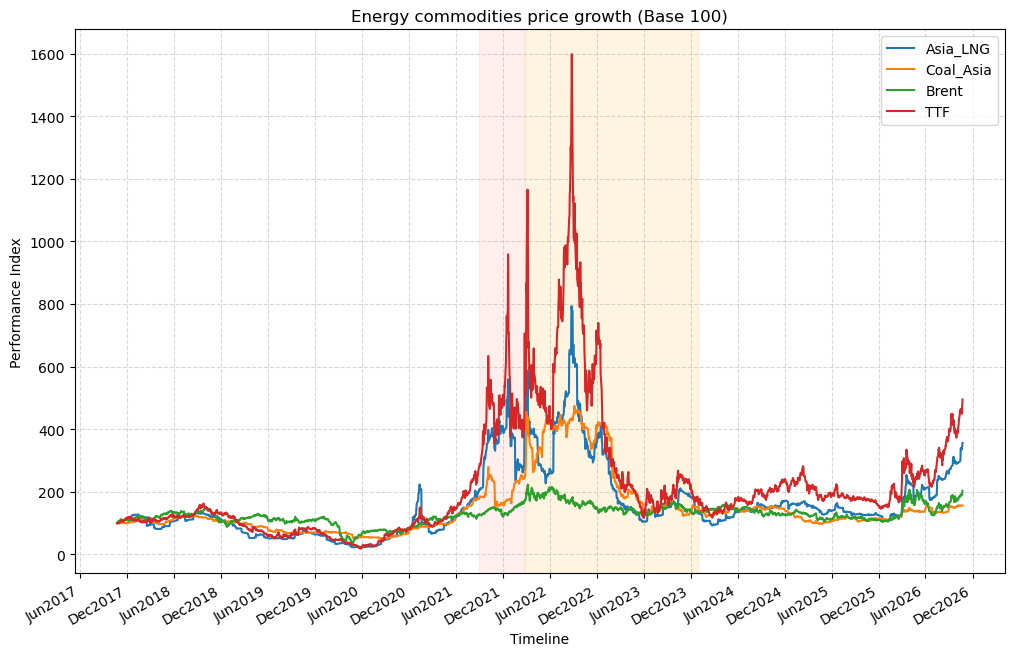

In [72]:
df_indexed = df_data.drop(columns=['WTI', 'Gas_Europe', 'Exchange_Rate'])
df_indexed = df_indexed.set_index('Date')

df_indexed = df_indexed.div(df_indexed.iloc[0]).mul(100)

fig, ax = plt.subplots(figsize=(12, 8))
df_indexed.plot(ax=ax)

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b%Y'))

ax.axvspan(pd.Timestamp('2021-09-01'), pd.Timestamp('2022-02-23'),
           color='salmon', alpha=0.12)
ax.axvspan(pd.Timestamp('2022-02-24'), pd.Timestamp('2023-12-31'),
           color='orange', alpha=0.12)

plt.title('Energy commodities price growth (Base 100)')
plt.ylabel('Performance Index')
plt.xlabel('Timeline')
plt.grid(True, linestyle='--', alpha=0.5)
plt.gcf().autofmt_xdate()
plt.show()

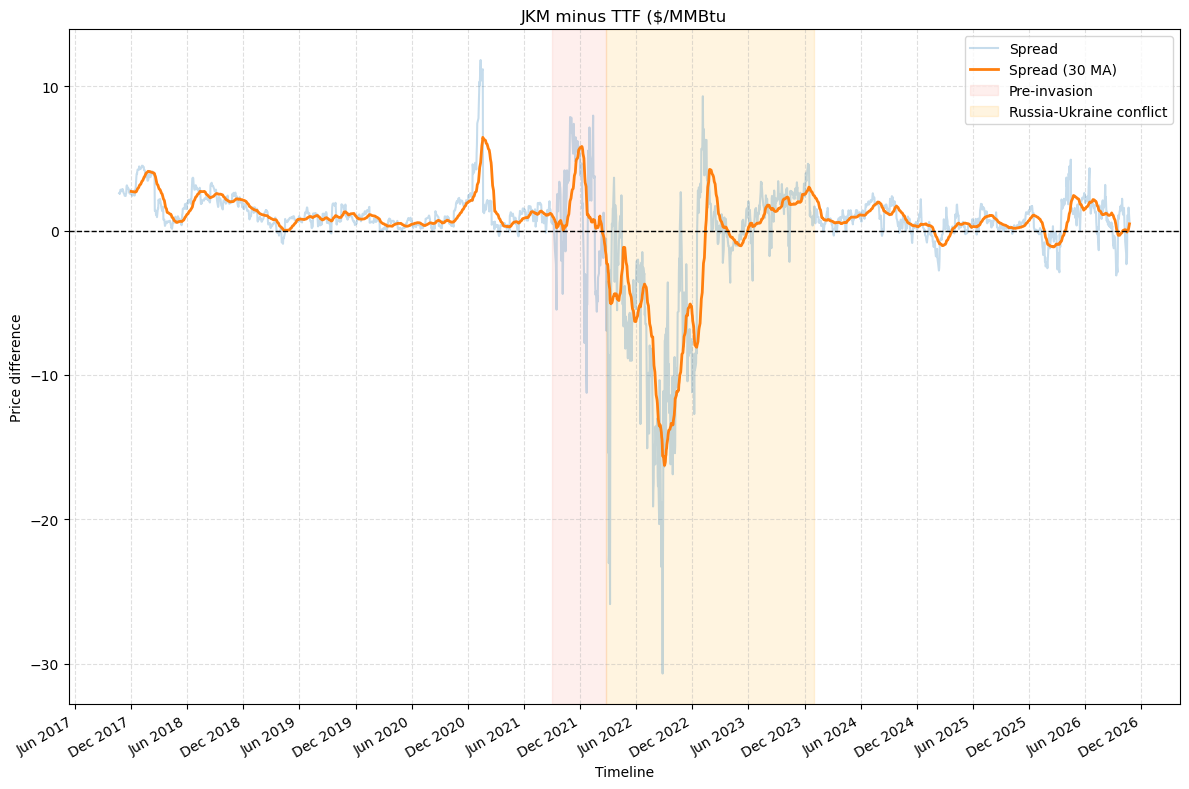

In [75]:
df_data['TTF Convert'] = (df_data['TTF']/3.412).round(2)
df_data['Spread'] = (df_data['Asia_LNG'] - df_data['TTF Convert']).round(2)

df_graph = df_data[['Date','Spread']].copy()

fig, ax = plt.subplots(figsize=(12, 8))

for col in df_graph.select_dtypes(include='number').columns:
    ax.plot(df_graph ['Date'], df_graph [col], alpha=0.25, label=col)
    ax.plot(df_data['Date'], df_data[col].rolling(30).mean(),
            linewidth=2, label=f'{col} (30 MA)')

ax.axhline(y=0, color='black', linestyle='--', linewidth=1)
ax.axvspan(pd.Timestamp('2021-09-01'), pd.Timestamp('2022-02-23'),
           color='salmon', alpha=0.12, label='Pre-invasion')
ax.axvspan(pd.Timestamp('2022-02-24'), pd.Timestamp('2023-12-31'),
           color='orange', alpha=0.12, label='Russia-Ukraine conflict')


ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

ax.set_title('JKM minus TTF ($/MMBtu')
ax.set_xlabel('Timeline')
ax.set_ylabel('Price difference')
ax.grid(True, linestyle='--', alpha=0.4)

plt.gcf().autofmt_xdate()
plt.legend()
plt.tight_layout()
plt.show()

Brent and Gas price increased 3-4 months prior to full Russia invasion of Ukraine, Brent dipped around 2021 $66 and rose sharply to $75-$89
by February it was at $96, TTF moved from $14 on average to $37/ MMBtu a record high in November/December and then dropping in January to $27 
before jumping right after February 2022.
Prior to February the JMK was higher than TTF due to Asia LNG relying on seaborne LNG, while the pipeline had the advantage to make TTF cheaper ,
to prevent energy collapse TTF traded at an unprecedent premium over JKM. 

Noted also that around March-April 2025 and February 2026 TTF traded over JMK , after winter demand peak and while storage as it lowest. This will be part of another study

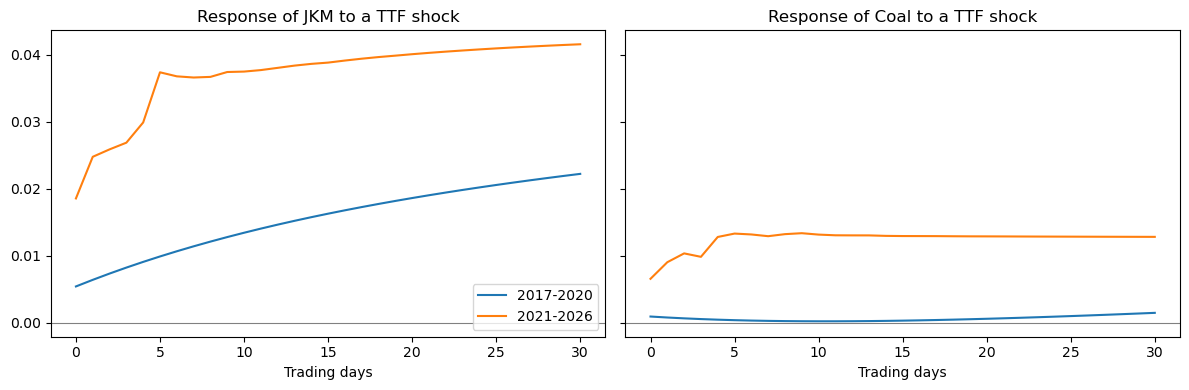

In [81]:
irf_a = vecm_res_1.irf(30)
irf_b = vecm_res_2.irf(30)

i_ttf, i_jkm, i_coal = cols_num.index('Gas_Europe'), cols_num.index('Asia_LNG'), cols_num.index('Coal_Asia')

fig, ax = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for a, (name, i) in zip(ax, [('JKM', i_jkm), ('Coal', i_coal)]):
    a.plot(irf_a.orth_irfs[:, i, i_ttf], label='2017-2020')
    a.plot(irf_b.orth_irfs[:, i, i_ttf], label='2021-2026')
    a.axhline(0, color='grey', lw=0.8)
    a.set_title(f'Response of {name} to a TTF shock')
    a.set_xlabel('Trading days')

ax[0].legend()
plt.tight_layout()
plt.show()